In [59]:
import numpy as np
from scipy import interpolate
import matplotlib.pyplot as plt

In [60]:
fs = 128

In [70]:
# Physiologically acceptable range of HR and distances between R.
# Signals outside of it are treated like acquisition error and filtered out.
PHYSIO_HR = np.array([30, 200])
PHYSIO_RR = (60 / PHYSIO_HR)[::-1]
PHYSIO_RR

array([0.3, 2. ])

In [62]:
np.loadtxt("data/nsr001.dat")

array([0.797, 0.695, 0.711, ..., 0.594, 0.578, 0.555], shape=(106460,))

RR_chf.shape=(135470,)


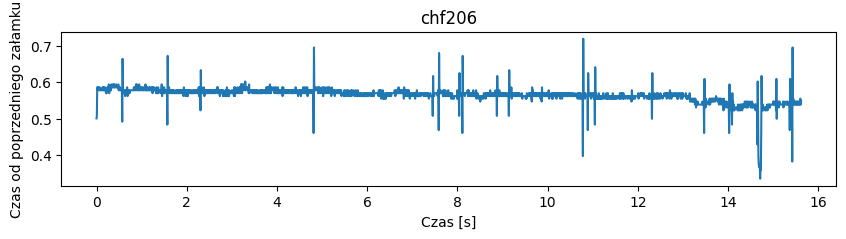

In [63]:
RR_chf = np.loadtxt("data/chf206.dat")


print(f"{RR_chf.shape=}")

plt.figure(figsize=(10, 2))
plt.plot(np.arange(2000) / fs, RR_chf[:2000])
plt.xlabel("Czas [s]")
plt.ylabel("Czas od poprzedniego załamku")
plt.title("chf206")
plt.show()

In [64]:
# Filter out non-physiological
RR_filtered_chf = RR_chf[np.where(np.logical_and(RR_chf>=PHYSIO_RR[0], RR_chf<=PHYSIO_RR[1]))]
RR_filtered_chf.shape

(134838,)

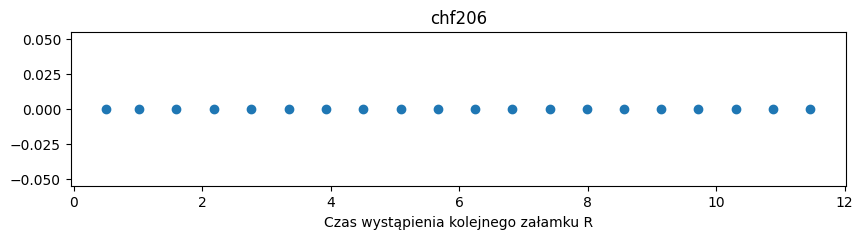

In [65]:
RR_chf_t = np.cumsum(RR_chf)

fragment_len = 20
plt.figure(figsize=(10, 2))
plt.scatter(RR_chf_t[:fragment_len], np.zeros(fragment_len))
plt.xlabel("Czas wystąpienia kolejnego załamku R")
plt.title("chf206")
plt.show()

In [66]:
RR_chf.min(), RR_chf.max()

(np.float64(0.25), np.float64(20.242))

RR_nsr.shape=(106460,)


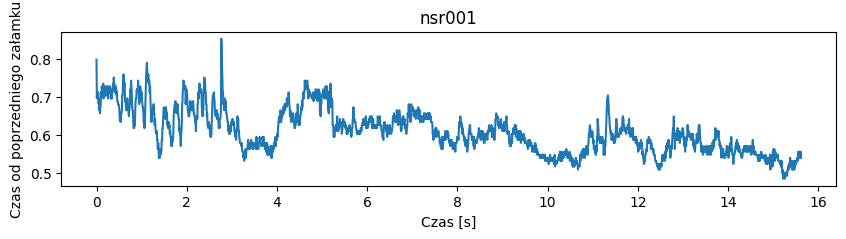

In [67]:
RR_nsr = np.loadtxt("data/nsr001.dat")

print(f"{RR_nsr.shape=}")

plt.figure(figsize=(10, 2))
plt.plot(np.arange(2000) / fs, RR_nsr[:2000])
plt.xlabel("Czas [s]")
plt.ylabel("Czas od poprzedniego załamku")
plt.title("nsr001")
plt.show()

In [68]:
RR_nsr.min(), RR_nsr.max()

(np.float64(0.305), np.float64(7.477))

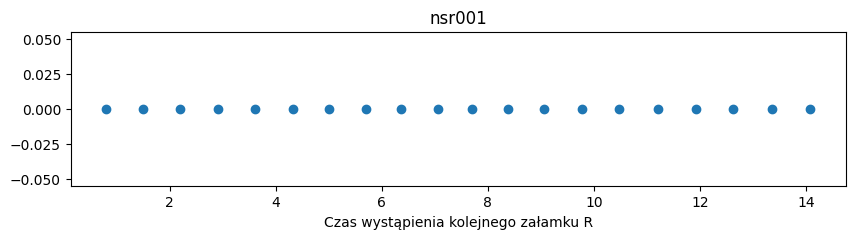

In [69]:
RR_nsr_t = np.cumsum(RR_nsr)

fragment_len = 20
plt.figure(figsize=(10, 2))
plt.scatter(RR_nsr_t[:fragment_len], np.zeros(fragment_len))
plt.xlabel("Czas wystąpienia kolejnego załamku R")
plt.title("nsr001")
plt.show()